# A/B-тест лендинга: повлияла ли новая версия страницы на конверсию?

**Учебный аналитический проект · продуктовая аналитика · Python / статистика**

## Контекст и постановка задачи

**Ситуация.** В учебном наборе данных представлены результаты эксперимента с двумя версиями лендинга: существующей (`old_page`) и новой (`new_page`). В работе целевое действие интерпретируется как **регистрация на курс**. Отдельного исходного бизнес-брифа в файле нет, поэтому эту формулировку рассматриваем как контекст учебного кейса, а не подтверждённые сведения о реальной компании.

**Продуктовый вопрос:** стоит ли рекомендовать переход на новую версию страницы, если задача — увеличить долю пользователей, совершивших целевое действие?

**Целевая метрика:** конверсия пользователей (`converted` = 1), в процентах. **Единица анализа:** уникальный пользователь; в исходном наборе данных до очистки возможны повторные строки на пользователя.

**Экспериментальные группы:** `control` → `old_page`, `treatment` → `new_page`.

**План анализа**
1. Проверить структуру данных, пропуски и временной диапазон.
2. Проверить соответствие назначения группы и показанной версии, устранить повторные наблюдения.
3. Проверить SRM при **предполагаемом** ожидаемом соотношении 50/50 (дизайн исходного эксперимента отдельно не предоставлен).
4. Сравнить конверсии, рассмотреть временную динамику.
5. Проверить двустороннюю гипотезу z-тестом разницы долей, построить 95% ДИ.
6. Проверить устойчивость вывода bootstrap и оценить чувствительность к MDE.
7. Сформулировать осторожную рекомендацию, не подменяя статистическую значимость бизнес-эффектом.

> **Данные:** файл `data_ab.csv` должен находиться рядом с Notebook. Исходный CSV не был приложен к портфолио, поэтому показанные ниже сохранённые результаты получены при первоначальном выполнении учебной работы и пока не воспроизведены в этой версии.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy import stats

# бутстрэп на будущее
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 120)


In [2]:
from pathlib import Path

DATA_PATH = Path("data_ab.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Не найден data_ab.csv. Положите исходный CSV в папку с Notebook "
        "(см. README.md)."
    )

df = pd.read_csv(DATA_PATH)
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2025-01-21 22:11:48.556739,control,old_page,0
1,804228,2025-01-12 08:01:45.159739,control,old_page,0
2,661590,2025-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2025-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2025-01-21 01:52:26.210827,control,old_page,1


**Ожидаемый результат исследования:** выяснить, есть ли свидетельства изменения конверсии при переходе на новую страницу. Сам факт отсутствия статистической значимости не доказывает равенства версий.

## 1. Знакомство с данными

**Задача этапа:** выяснить, сколько наблюдений доступно, какие переменные есть в датасете, имеются ли пропуски и за какой период собраны данные.

Основные поля: `user_id` — пользователь, `timestamp` — время наблюдения, `group` — группа эксперимента, `landing_page` — фактически показанная страница, `converted` — бинарный признак целевого действия.

Проверки ниже нужны, чтобы выбрать корректную единицу анализа и исключить нарушения качества данных до расчёта эффекта.

In [3]:
df.dtypes

user_id                  int64
timestamp       datetime64[ns]
group                   object
landing_page            object
converted                int64
dtype: object

In [4]:
df["timestamp"].min(), df["timestamp"].max()

(Timestamp('2025-01-02 13:42:05.378582'),
 Timestamp('2025-01-24 13:41:54.460509'))

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   user_id       294478 non-null  int64         
 1   timestamp     294478 non-null  datetime64[ns]
 2   group         294478 non-null  object        
 3   landing_page  294478 non-null  object        
 4   converted     294478 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 11.2+ MB


In [6]:
df.isna().sum()

user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64

## 2. Подготовка данных и контроль качества эксперимента

**Почему это важно:** статистический тест предполагает сопоставимые группы и корректное определение наблюдений. До оценки конверсии необходимо проверить:

- **Несоответствия назначения и показа:** `control` должен видеть `old_page`, `treatment` — `new_page`. В данном учебном анализе такие строки исключаются; это решение меняет анализируемую популяцию и в реальном эксперименте потребовало бы отдельной проверки причин.
- **Повторы `user_id`:** для метрики «конверсия на пользователя» оставляем первое корректное наблюдение каждого пользователя.
- **SRM:** сравним численность групп с ожидаемым соотношением 50/50; оно принято здесь как допущение, а не подтверждено техническим дизайном.
- **Временной профиль:** проверим, как число наблюдений менялось в течение эксперимента.

### 2.1. Повторные наблюдения и согласованность назначения

Сначала изучим частоты `user_id` и таблицу `group` × `landing_page`. Затем исключим несогласованные строки и оставим для каждого пользователя самое раннее корректное событие.

**Ограничение:** если пользователь мог менять группы или одна строка не соответствует полноценной попытке регистрации, такой способ очистки требует дополнительной продуктовой валидации.

In [7]:
# Кратко проверим количество пользователей с повторными наблюдениями.
rows_per_user = df.groupby("user_id").size()
print("Уникальных пользователей в исходных данных:", rows_per_user.size)
print("Пользователей с несколькими строками:", int((rows_per_user > 1).sum()))
print("Максимум строк на пользователя:", int(rows_per_user.max()))

Уникальных пользователей в исходных данных: 290584
Пользователей с несколькими строками: 3894
Максимум строк на пользователя: 2


In [8]:
#связь group и landing_page
pd.crosstab(df['group'], df['landing_page'])

landing_page,new_page,old_page
group,,
control,1928,145274
treatment,145311,1965


In [9]:
correct_mask = (
    ((df['group'] == 'control') & (df['landing_page'] == 'old_page')) |
    ((df['group'] == 'treatment') & (df['landing_page'] == 'new_page'))
)

df_correct = df[correct_mask].copy()

print("Строк всего:", len(df))
print("Строк после фильтра:", len(df_correct))

pd.crosstab(df_correct['group'], df_correct['landing_page'])

Строк всего: 294478
Строк после фильтра: 290585


landing_page,new_page,old_page
group,,
control,0,145274
treatment,145311,0


In [10]:
# Проверим дубликаты в очищенном df
dup_users = df_correct['user_id'].duplicated().sum()

print("Количество пользователей с повторяющимися user_id:", dup_users)

Количество пользователей с повторяющимися user_id: 1


In [11]:
# Сколько повторов осталось после проверки соответствия группы и страницы?
rows_per_user_correct = df_correct.groupby("user_id").size()
print("Повторных пользователей после фильтра:", int((rows_per_user_correct > 1).sum()))

Повторных пользователей после фильтра: 1


In [12]:
# Отсортируем по времени, чтобы учитывать "первый" визит
df_correct = df_correct.sort_values(by=['user_id', 'timestamp'])

#только один визит на каждого пользователя
df_clean = df_correct.drop_duplicates(subset='user_id', keep='first').copy()

print("Строк после удаления дубликатов по user_id:", len(df_clean))
print("Уникальных user_id:", df_clean['user_id'].nunique())
print("Повторяющихся user_id после очистки:", df_clean['user_id'].duplicated().sum())

Строк после удаления дубликатов по user_id: 290584
Уникальных user_id: 290584
Повторяющихся user_id после очистки: 0


In [13]:
df_clean.head()

,user_id,timestamp,group,landing_page,converted
63114,630000,2025-01-19 06:26:06.548941,treatment,new_page,0
103873,630001,2025-01-16 03:16:42.560309,treatment,new_page,1
205236,630002,2025-01-19 19:20:56.438330,control,old_page,0
247344,630003,2025-01-12 10:09:31.510471,treatment,new_page,0
242283,630004,2025-01-18 20:23:58.824994,treatment,new_page,0


### 2.2. SRM — проверка распределения трафика

**Вопрос:** не выглядит ли соотношение пользователей между группами подозрительным при допущении о планируемом сплите 50/50?

Применим χ²-критерий согласия. Нулевая гипотеза — пропорции соответствуют 50/50. Большое p-value **не доказывает** правильность рандомизации: тест выявляет лишь определённый вид перекоса.

In [14]:
# SRM: chi-square на равенство долей групп (ожидаем 50/50)
from scipy.stats import chisquare

group_counts = df_clean["group"].value_counts()
n_control = group_counts.loc["control"]
n_treatment = group_counts.loc["treatment"]
n_total = n_control + n_treatment

chi2, p_srm = chisquare(
    f_obs=[n_control, n_treatment], #наблюдаемые частоты
    f_exp=[n_total / 2, n_total / 2] #ожидаемые
)

group_counts, chi2, p_srm

(group
 treatment    145310
 control      145274
 Name: count, dtype: int64,
 np.float64(0.004459984032155934),
 np.float64(0.9467543681597944))

**Результат расчёта по приложенному CSV:** χ² ≈ 0,00446, p ≈ 0,947. При α = 0,05 нет оснований отвергнуть гипотезу о соотношении групп 50/50. Это **не является доказательством**, что механизм рандомизации был безошибочным.

### 2.3. Временная динамика участников

Проверим дневное число пользователей по группам. Если графики существенно расходятся на отдельном участке, это повод отдельно проверить сбор данных, источники трафика и даты запуска.

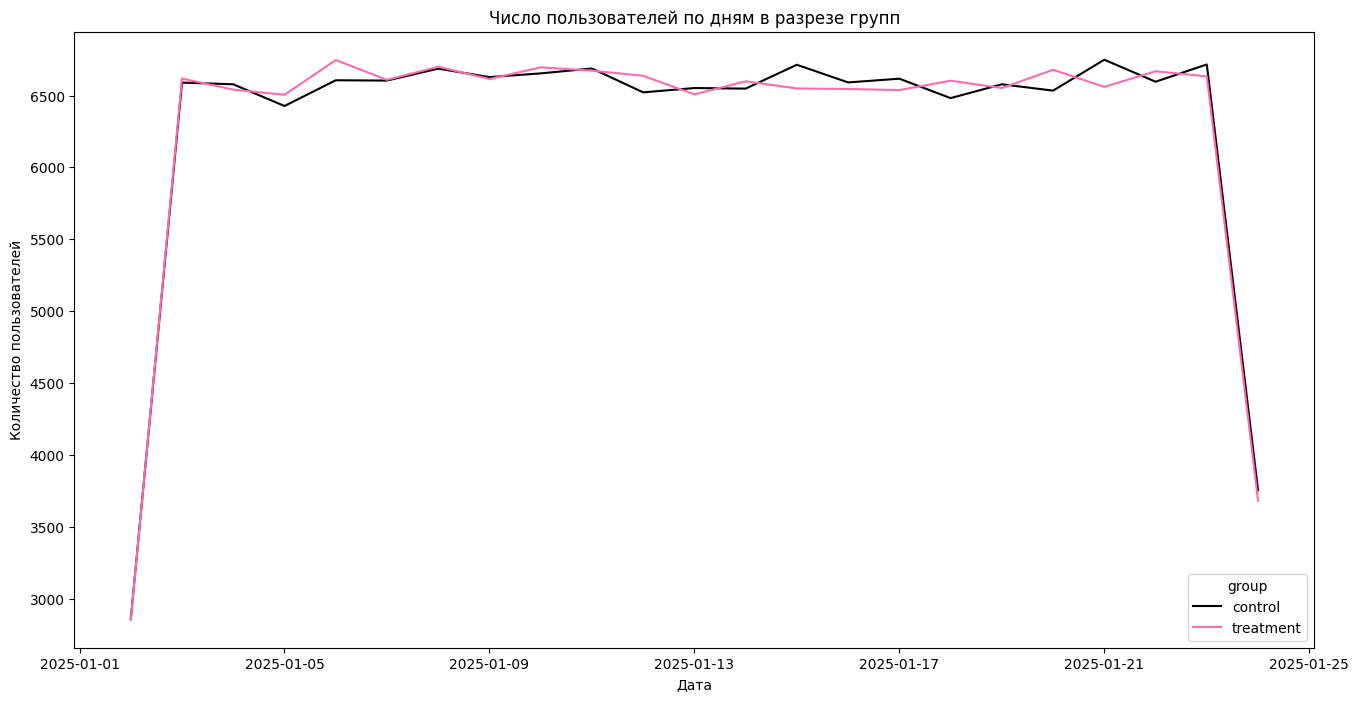

In [15]:
# Время берём из уже очищенного набора, сохраняя соответствие user_id ↔ timestamp.
df_clean["timestamp"] = pd.to_datetime(df_clean["timestamp"], errors="coerce")
df_clean["date"] = df_clean["timestamp"].dt.date
users_per_day = df_clean.groupby(["date", "group"])["user_id"].count().reset_index()
plt.figure(figsize=(16, 8))
palette = {"control": "black", "treatment": "hotpink"}
sns.lineplot(data=users_per_day, x="date", y="user_id", hue="group", palette=palette)
plt.title("Число пользователей по дням в разрезе групп")
plt.xlabel("Дата")
plt.ylabel("Количество пользователей")
plt.show()

## 3. Анализ целевой метрики

**Задача:** оценить конверсию отдельно в контрольной и тестовой группах и вычислить разницу между ними.

$$CR = \frac{\text{число пользователей с } converted=1}{\text{число пользователей в группе}} \times 100\%$$

После очистки один пользователь представлен одной строкой. Разницу считаем как **treatment − control** в процентных пунктах (п.п.), а не процентах относительного изменения.

In [16]:
# Конверсия по группам
conv = df_clean.groupby("group")["converted"].agg(["mean", "sum", "count"]).rename(columns={"mean": "cr"})
conv["cr_percent"] = conv["cr"] * 100
conv

,cr,sum,count,cr_percent
group,,,,
control,0.120386,17489,145274,12.038630
treatment,0.118808,17264,145310,11.880807


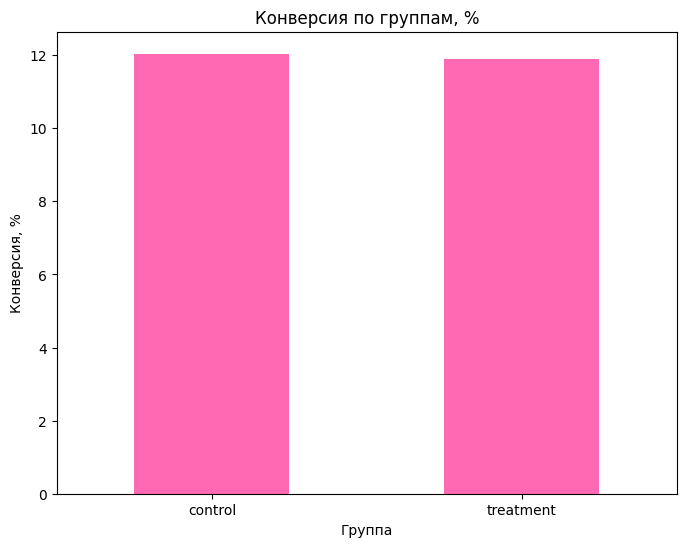

In [17]:
ax = (conv["cr"] * 100).plot(kind="bar", figsize=(8, 6), color='hotpink')
ax.set_title("Конверсия по группам, %")
ax.set_xlabel("Группа")
ax.set_ylabel("Конверсия, %")
plt.xticks(rotation=0)
plt.show()

### Дополнительная разведка: день недели

Посмотрим, меняются ли описательные конверсии по дням недели. Это **исследовательский анализ**: без поправок на множественные проверки и отдельной модели делать причинные выводы о влиянии дня недели нельзя.

In [18]:
# Конверсии по дням недели
df_clean["dow"] = df_clean["timestamp"].dt.day_name()

pivot_dow = df_clean.pivot_table(index="dow", columns="group", values="converted", aggfunc="mean").sort_index()
pivot_dow * 100


group,control,treatment
dow,,
Friday,11.674783,12.233884
Monday,11.583384,11.753787
Saturday,12.183512,11.883736
Sunday,12.172889,11.820859
Thursday,12.279547,11.949130
Tuesday,12.456660,11.705787
Wednesday,11.951793,11.743147


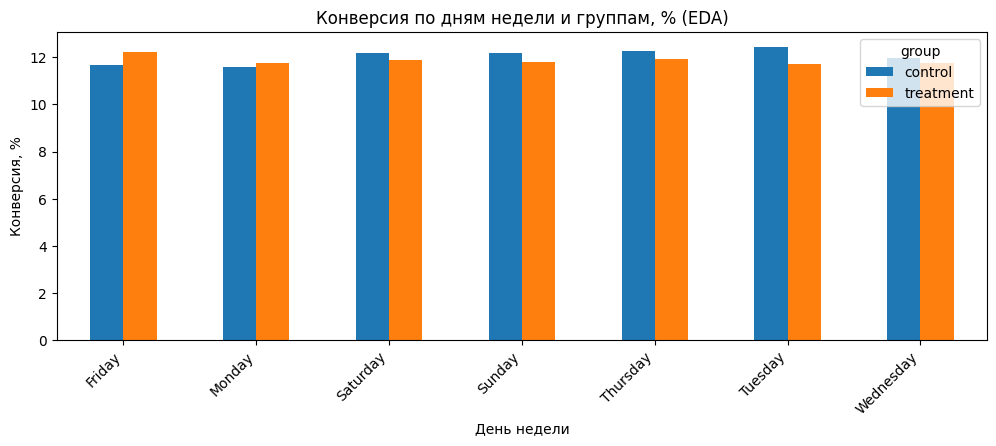

In [19]:
# Визуализация: конверсия по дням недели
ax = (pivot_dow * 100).plot(kind="bar", figsize=(12, 4))
ax.set_title("Конверсия по дням недели и группам, % (EDA)")
ax.set_xlabel("День недели")
ax.set_ylabel("Конверсия, %")
plt.xticks(rotation=45, ha="right")
plt.show()

## 4. Статистические гипотезы

- **H₀:** $p_{treatment} = p_{control}$ (конверсии равны).
- **H₁:** $p_{treatment} \ne p_{control}$ (конверсии различаются).
- **α = 0,05**, двусторонняя проверка.

Такая гипотеза отвечает на вопрос об **изменении** метрики, а не исключительно о её росте. Для решения о внедрении важны также направление эффекта, неопределённость и заранее определённый экономически значимый порог.

## 5. z-тест для двух долей и доверительный интервал

**Почему этот метод:** `converted` — бинарный исход, а выборки двух групп велики. Для проверки H₀ используем z-тест с **объединённой (pooled) оценкой доли в стандартной ошибке**.

**Для доверительного интервала** разницы долей используем **необъединённую (unpooled) стандартную ошибку**: это отдельная оценка неопределённости наблюдаемого эффекта, а не ошибка для проверки H₀.

Проверяем не только p-value, но и размер эффекта в п.п. с 95% ДИ.

In [20]:
# z-тест разницы долей (двусторонний)

# Данные по группам
n1 = int(conv.loc["control", "count"])
x1 = int(conv.loc["control", "sum"])
p1 = x1 / n1

n2 = int(conv.loc["treatment", "count"])
x2 = int(conv.loc["treatment", "sum"])
p2 = x2 / n2

diff = p2 - p1

# pooled proportion для H0
p_pool = (x1 + x2) / (n1 + n2)
se = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))

z = diff / se
p_value = 2 * (1 - stats.norm.cdf(abs(z))) # т.к. z < 0, вычитаем из 1 z по модулю

diff, z, p_value

(-0.0015782389853555567,
 np.float64(-1.3109241984234394),
 np.float64(0.18988337448195103))

In [21]:
# 95% ДИ для разницы долей: необъединённая стандартная ошибка.
alpha = 0.05
z_crit = stats.norm.ppf(1 - alpha / 2)
se_ci = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
ci_low = diff - z_crit * se_ci
ci_high = diff + z_crit * se_ci
(ci_low, ci_high)

(np.float64(-0.003937860245052736), np.float64(0.0007813822743416229))

**Интерпретация результатов расчёта:** конверсия контроля ≈ **12,039%**, тестовой группы ≈ **11,881%**; наблюдаемая разница ≈ **−0,158 п.п.** z ≈ −1,311, двустороннее p ≈ **0,190**.

При α = 0,05 не отвергаем H₀. Доверительный интервал разницы охватывает ноль, то есть данные совместимы как с небольшим отрицательным, так и с небольшим положительным эффектом. **Необнаруженный эффект ≠ доказанное отсутствие эффекта.** Экономика внедрения неизвестна.

## 6. Bootstrap: проверка устойчивости оценки

**Задача:** получить эмпирическое распределение разницы конверсий без опоры исключительно на нормальную аппроксимацию.

В каждой итерации отдельно пересэмплируем пользователей внутри контрольной и тестовой групп, считаем конверсии и сохраняем их разницу. Используем percentile 95% ДИ.

Это дополнительная оценка неопределённости, а не второй независимый эксперимент.

In [22]:
# Bootstrap для разницы конверсий

def bootstrap_diff(df_in: pd.DataFrame, n_boot: int = 5000, seed: int = RANDOM_SEED):
    rng_local = np.random.default_rng(seed)
    control = df_in.loc[df_in["group"] == "control", "converted"].to_numpy()
    treat = df_in.loc[df_in["group"] == "treatment", "converted"].to_numpy()

    n_c = control.size
    n_t = treat.size

    diffs = np.empty(n_boot, dtype=float)

    for i in range(n_boot):
        c_sample = rng_local.choice(control, size=n_c, replace=True)
        t_sample = rng_local.choice(treat, size=n_t, replace=True)
        diffs[i] = t_sample.mean() - c_sample.mean()

    return diffs

boot_diffs = bootstrap_diff(df_clean, n_boot=3000)
boot_ci = (np.percentile(boot_diffs, 2.5), np.percentile(boot_diffs, 97.5))

boot_ci


(np.float64(-0.0038150561708717957), np.float64(0.0009066047350312248))

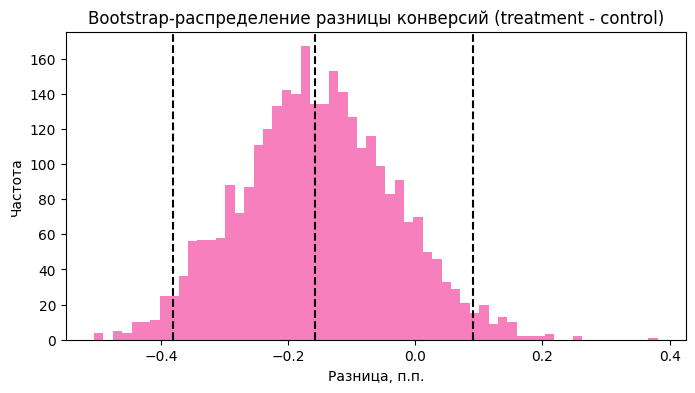

In [23]:
plt.figure(figsize=(8, 4))
plt.hist(boot_diffs * 100, bins=60, color='#F77FBE')
plt.title("Bootstrap-распределение разницы конверсий (treatment - control)")
plt.xlabel("Разница, п.п.")
plt.ylabel("Частота")
plt.axvline(diff * 100, linestyle="--", color='black')
plt.axvline(boot_ci[0] * 100, linestyle="--", color='black')
plt.axvline(boot_ci[1] * 100, linestyle="--", color='black')
plt.show()


**Результат расчёта:** bootstrap 95% ДИ ≈ **[−0,382; +0,091] п.п.** Интервал включает ноль и согласуется с основным тестом. Это не означает, что истинные конверсии двух групп доказанно совпадают.

## 7. Чувствительность эксперимента: MDE и объём выборки

**Бизнес-вопрос:** насколько большой эксперимент нужен, чтобы обнаруживать изменения конверсии на 0,2, 0,5 или 1,0 процентного пункта?

Ниже — **ориентировочный расчёт планового размера выборки** на группу для двусторонней проверки при α = 0,05 и мощности 80%, если контрольная конверсия близка к наблюдаемой.

Эти расчёты нельзя трактовать как ретроспективное доказательство мощности уже состоявшегося теста. Выбор MDE в реальном продукте должен опираться на экономику продукта.

In [24]:
from math import ceil #потолок

def sample_size_two_proportions(p1: float, p2: float, alpha: float = 0.05, power: float = 0.8) -> int:
    z_alpha = stats.norm.ppf(1 - alpha / 2)
    z_beta = stats.norm.ppf(power)

    p_bar = (p1 + p2) / 2
    q_bar = 1 - p_bar

    num = (z_alpha * np.sqrt(2 * p_bar * q_bar) + z_beta * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2
    den = (p2 - p1) ** 2
    return int(ceil(num / den))

baseline = p1

for mde in [0.002, 0.005, 0.01]:
    needed = sample_size_two_proportions(baseline, baseline + mde, alpha=0.05, power=0.8)
    print(f"MDE = {mde*100:.1f} п.п. -> нужно примерно {needed:,} пользователей на группу")


MDE = 0.2 п.п. -> нужно примерно 418,547 пользователей на группу
MDE = 0.5 п.п. -> нужно примерно 67,679 пользователей на группу
MDE = 1.0 п.п. -> нужно примерно 17,214 пользователей на группу


## 8. Итог и продуктовая рекомендация

### Что сделано

- Проанализированы события эксперимента двух версий лендинга за **2–24 января 2025 года** (по исходному датасету).
- Исходно **294 478 строк**, после исключения несовпадений `group`/`landing_page` и повторных пользователей — **290 584 пользователя**.
- Проверены баланс трафика (SRM), временная динамика и конверсии в двух группах.
- Рассчитаны z-тест для разницы долей, 95% доверительный интервал и bootstrap-оценка.

### Основные результаты

| Показатель | Результат повторного расчёта |
|---|---:|
| Конверсия control | 12,039% |
| Конверсия treatment | 11,881% |
| Разница treatment − control | **−0,158 п.п.** |
| Двустороннее p-value z-теста | **0,190** |
| Bootstrap 95% ДИ | **[−0,382; +0,091] п.п.** |
| SRM p-value (ожидаемый сплит 50/50) | **0,947** |

### Вывод

**Статистически убедительных свидетельств изменения конверсии на уровне 5% не обнаружено.** Точечная оценка эффекта отрицательна, но интервал неопределённости пересекает ноль. По представленным результатам **не стоит рекомендовать запуск новой страницы исключительно ради повышения конверсии**.

### Что проверить до реального продуктового решения

1. Подтвердить, что `converted` действительно отражает регистрацию на курс и что сплит планировался 50/50.
2. Изучить причины несовпадения назначения и фактического показа; оценить влияние исключения этих наблюдений.
3. Зафиксировать минимальный бизнес-эффект, оправдывающий внедрение, и затраты на него.
4. При необходимости спланировать новый эксперимент под выбранный MDE и дополнительные метрики.

**Ограничения:** исходный CSV и технический бриф не приложены; данные и результаты в Notebook сохранились от предыдущего выполнения, а изменённые ячейки не были заново выполнены на исходном датасете. В работе не использовалась байесовская модель; причинные выводы ограничены доступной информацией о дизайне эксперимента.